<a href="https://colab.research.google.com/github/PratikshaYadav8799/Python_Programming/blob/main/Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
#Prepare 1D Data Series
One_Dseries=pd.Series([1,2,3])

#Display the series
print(One_Dseries)

0    1
1    2
2    3
dtype: int64


In [ ]:
One_Dseries=pd.Series([1,2,2])
print(One_Dseries)

0    1
1    2
2    2
dtype: int64


In [ ]:
data1=pd.Series({'India':100,'USA':200})
data1

,0
India,100
USA,200


In [ ]:
data2=pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Name':['A','B','C','D','E','F','G','H','I','J'],
    'Marks':[10,20,30,40,50,60,70,80,90,100],
    'CGPA':[9,8,7,5,4,2,5,7,5,9]
})
data2

,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,5
4,5,E,50,4
5,6,F,60,2
6,7,G,70,5
7,8,H,80,7
8,9,I,90,5
9,10,J,100,9


In [ ]:
#Checking Dataset Information
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   SrNo    10 non-null     int64 
 1   Name    10 non-null     object
 2   Marks   10 non-null     int64 
 3   CGPA    10 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 452.0+ bytes


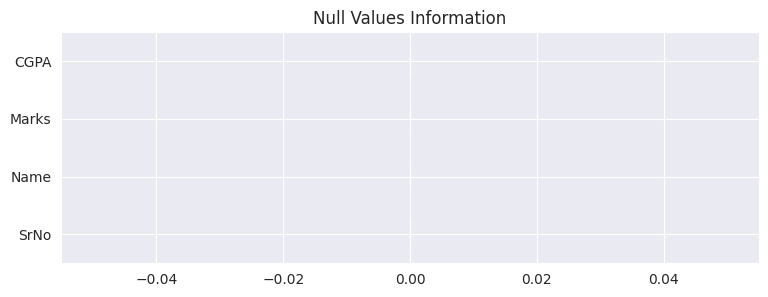

In [ ]:
#Checking Null Values Information
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

plt.figure(figsize=(9,3))
data2.isnull().sum().plot(kind='barh')
plt.title('Null Values Information')
plt.show()

In [ ]:
#Checking Duplicated Values
data2.duplicated() #Helps us to check the duplicate records present in dataset
data2.drop_duplicates() #This will drop the duplicated records from the dataset

,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,5
4,5,E,50,4
5,6,F,60,2
6,7,G,70,5
7,8,H,80,7
8,9,I,90,5
9,10,J,100,9


In [ ]:
#Checking Descriptive Stats for Numerical Columnns
data2.describe(exclude='object')

,SrNo,Marks,CGPA
count,10.00000,10.000000,10.000000
mean,5.50000,55.000000,6.100000
std,3.02765,30.276504,2.282786
min,1.00000,10.000000,2.000000
25%,3.25000,32.500000,5.000000
50%,5.50000,55.000000,6.000000
75%,7.75000,77.500000,7.750000
max,10.00000,100.000000,9.000000


In [ ]:
#Checking Descriptive Stats for Categorical Columns
data2.describe(include='object')

,Name
count,10
unique,10
top,A
freq,1


In [ ]:
#Checking Descriptive Stats

from numpy import quantile

#Step1:Segregate Categorical and Numerical Columns
numerical_column=data2.select_dtypes(exclude=['object']).columns
categorical_column=data2.select_dtypes(include=['object']).columns


#Step2:Create Empty List
stats=[]
from collections import OrderedDict
for i in numerical_column:
  numerical_stats=OrderedDict({
      'Feature':i,
      'Count':data2[i].count(),
      '% of Missing Values':(data2[i].isnull().sum() / len(data2))*100,
      'Minimum':data2[i].min(),
      'Maximum':data2[i].max(),
      'Mean':data2[i].mean(),
      'Median':data2[i].median(),
      'Q1':data2[i].quantile(0.25),
      'Q3':data2[i].quantile(0.75),
      'IQR':data2[i].quantile(0.75)-data2[i].quantile(0.25),
      'Variance':data2[i].var(),
      'Standard Deviation':data2[i].std(),
      'Skewness':data2[i].skew(),
      'Kurtosis':data2[i].kurtosis()

  })



  stats.append(numerical_stats)
  report=pd.DataFrame(stats)

report


,Feature,Count,% of Missing Values,Minimum,Maximum,Mean,Median,Q1,Q3,IQR,Variance,Standard Deviation,Skewness,Kurtosis
0,Sr.No,5,0.0,1,5,3.0,3.0,2.0,4.0,2.0,2.5,1.581139,0.000000,-1.200000
1,Marks,5,0.0,10,50,30.0,30.0,20.0,40.0,20.0,250.0,15.811388,0.000000,-1.200000
2,CGPA,5,0.0,4,9,6.6,7.0,5.0,8.0,3.0,4.3,2.073644,-0.235514,-1.963223


In [ ]:
#Saving Report File as CSV
report.to_csv('Report.csv')